## Notebook 3 — Exploratory Data Analysis
1.We’ll follow this order:

2.Load and verify datasets

3.Real complaint volumes and product trends — full dataset

4.Company and state analysis — full dataset

5.Response/timeliness KPIs — full dataset

6.Equal-product comparisons — balanced dataset

7.Save EDA tables and figures

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

In [31]:
DATA_DIR = Path("../data/processed")

full_df = pd.read_csv(
    DATA_DIR / "cleaned_full_data.csv",
    low_memory=False
)

balanced_df = pd.read_csv(
    DATA_DIR / "balanced_analytical_data.csv",
    low_memory=False
)

print("Full cleaned dataset:", full_df.shape)
print("Balanced analytical dataset:", balanced_df.shape)

Full cleaned dataset: (566694, 26)
Balanced analytical dataset: (144697, 26)


## 1. Overall Complaint Volume and Coverage

This section examines the overall size and coverage of the complaint dataset. The full cleaned dataset is used because it preserves the actual number of complaints received for each product, company, state, and time period.

In [32]:
print("COLUMNS")
print(full_df.columns.tolist())

print("\nFULL DATASET — REAL PRODUCT VOLUMES")
display(
    full_df["product"]
    .value_counts()
    .rename_axis("product")
    .reset_index(name="complaints")
)

print("\nBALANCED DATASET — COMPARISON SAMPLE")
display(
    balanced_df["product"]
    .value_counts()
    .rename_axis("product")
    .reset_index(name="complaints")
)

COLUMNS
['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'complaint_id', 'source_file', 'has_narrative', 'narrative_character_count', 'narrative_word_count', 'cleaned_narrative', 'has_cleaned_narrative', 'narrative_repeat_count', 'is_repeated_narrative', 'zip_code_status', 'zip3']

FULL DATASET — REAL PRODUCT VOLUMES


,product,complaints
0,Debt collection,283205
1,Credit card,89979
2,"Money transfer, virtual currency, or money ser...",84619
3,Checking or savings account,84194
4,Mortgage,24697



BALANCED DATASET — COMPARISON SAMPLE


,product,complaints
0,"Money transfer, virtual currency, or money ser...",30000
1,Checking or savings account,30000
2,Debt collection,30000
3,Credit card,30000
4,Mortgage,24697


### 1.1 Date Preparation

The `date_received` column is converted to datetime format to support time-based analysis. A monthly period variable is also created for examining complaint trends over time. This is an analytical transformation and does not change the underlying complaint records.

In [33]:
full_df["date_received"] = pd.to_datetime(
    full_df["date_received"],
    errors="coerce"
)

full_df["year_month"] = full_df["date_received"].dt.to_period("M").astype(str)

print("Earliest complaint:", full_df["date_received"].min())
print("Latest complaint:", full_df["date_received"].max())
print("Invalid dates:", full_df["date_received"].isna().sum())
print("Number of months:", full_df["year_month"].nunique())

Earliest complaint: 2025-01-01 00:00:29+00:00
Latest complaint: 2025-12-31 23:58:31+00:00
Invalid dates: 0
Number of months: 12


/var/folders/kf/zl0ktfsd2d577bprgzdycbzr0000gn/T/ipykernel_11954/239691940.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  full_df["year_month"] = full_df["date_received"].dt.to_period("M").astype(str)


### 1.2 Dataset Overview

The following summary provides the main coverage indicators for the dataset, including the total number of complaints, products, companies, states, and the available date range.

In [34]:
overall_kpis = pd.Series({
    "Total complaints": len(full_df),
    "Products": full_df["product"].nunique(),
    "Companies": full_df["company"].nunique(),
    "States": full_df["state"].nunique(),
    "Start date": full_df["date_received"].min().date(),
    "End date": full_df["date_received"].max().date()
})

display(overall_kpis.to_frame("value"))

,value
Total complaints,566694
Products,5
Companies,3326
States,61
Start date,2025-01-01
End date,2025-12-31


### 1.3 Complaint Volume by Product

Complaint counts and percentage shares are calculated using the full cleaned dataset. This preserves the true distribution of complaints across the five selected financial products.

In [35]:
product_volume = (
    full_df["product"]
    .value_counts()
    .rename_axis("product")
    .reset_index(name="complaints")
)

product_volume["percentage"] = (
    product_volume["complaints"] / len(full_df) * 100
).round(2)

display(product_volume)

,product,complaints,percentage
0,Debt collection,283205,49.97
1,Credit card,89979,15.88
2,"Money transfer, virtual currency, or money ser...",84619,14.93
3,Checking or savings account,84194,14.86
4,Mortgage,24697,4.36


### 1.4 Product Volume Visualisation

The bar chart compares the actual number of complaints across products. Since the objective is to show real complaint volume, the full dataset is used rather than the balanced analytical subset.

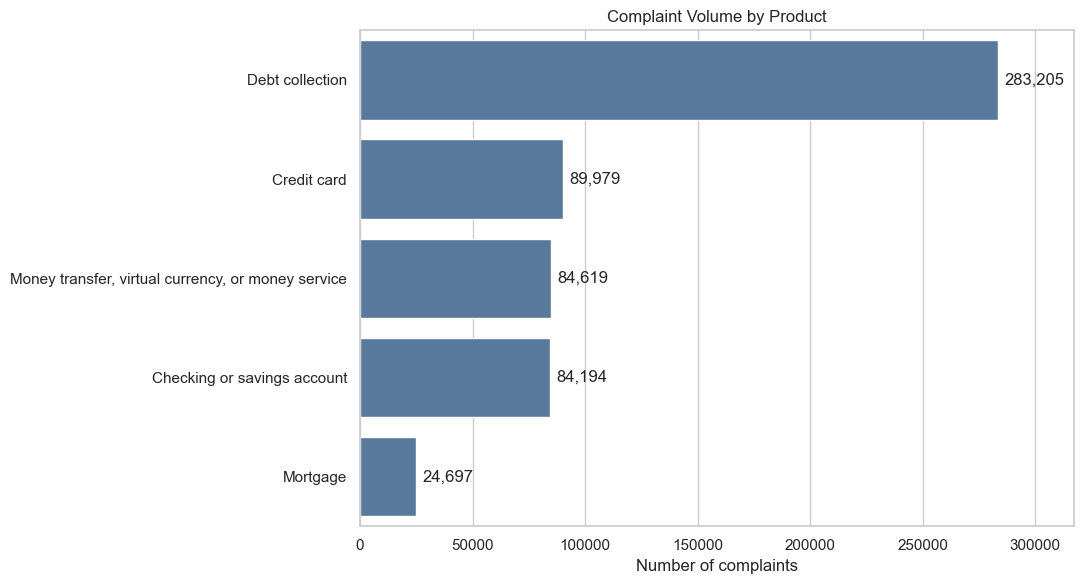

In [36]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=product_volume,
    x="complaints",
    y="product",
    color="#4C78A8"
)

# Add correctly formatted labels
for container in ax.containers:
    labels = [f"{value:,.0f}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=5)

# Leave space for labels
ax.set_xlim(0, product_volume["complaints"].max() * 1.12)

plt.title("Complaint Volume by Product")
plt.xlabel("Number of complaints")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Interpretation:**  
The chart highlights differences in actual complaint volume across financial products. Debt collection represents the largest share of complaints in the dataset, while mortgage complaints have the lowest volume. These differences reflect the original CFPB complaint records and should not be interpreted as direct measures of product quality or market size.

## 2. Complaint Trends Over Time

This section analyses complaint volumes over time using the full cleaned dataset. The original timestamp is retained, while separate calendar-date and month variables are created for daily and monthly aggregation. This prevents individual times within the same day from being treated as separate dates.

In [37]:
# Convert the original field into a consistent UTC timestamp
full_df["received_timestamp"] = pd.to_datetime(
    full_df["date_received"],
    errors="coerce",
    utc=True
)

# Calendar date for daily analysis
full_df["received_date"] = (
    full_df["received_timestamp"]
    .dt.normalize()
    .dt.tz_localize(None)
)

# First day of the month for monthly analysis
full_df["received_month"] = (
    full_df["received_timestamp"]
    .dt.tz_localize(None)
    .dt.to_period("M")
    .dt.to_timestamp()
)

time_validation = pd.Series({
    "Total rows": len(full_df),
    "Valid timestamps": full_df["received_timestamp"].notna().sum(),
    "Invalid timestamps": full_df["received_timestamp"].isna().sum(),
    "Earliest timestamp": full_df["received_timestamp"].min(),
    "Latest timestamp": full_df["received_timestamp"].max(),
    "Unique calendar days": full_df["received_date"].nunique(),
    "Unique months": full_df["received_month"].nunique()
})

display(time_validation.to_frame("value"))

,value
Total rows,566694
Valid timestamps,566694
Invalid timestamps,0
Earliest timestamp,2025-01-01 00:00:29+00:00
Latest timestamp,2025-12-31 23:58:31+00:00
Unique calendar days,365
Unique months,12


### 2.1 Overall Monthly Complaint Trend

Complaints are aggregated by calendar month to examine changes in total complaint volume during 2025. The time component of each record does not affect the monthly totals.

,received_month,complaints
0,2025-01-01,103217
1,2025-02-01,36579
2,2025-03-01,36550
3,2025-04-01,36780
4,2025-05-01,39489
5,2025-06-01,39092
6,2025-07-01,44376
7,2025-08-01,44976
8,2025-09-01,45987
9,2025-10-01,45552


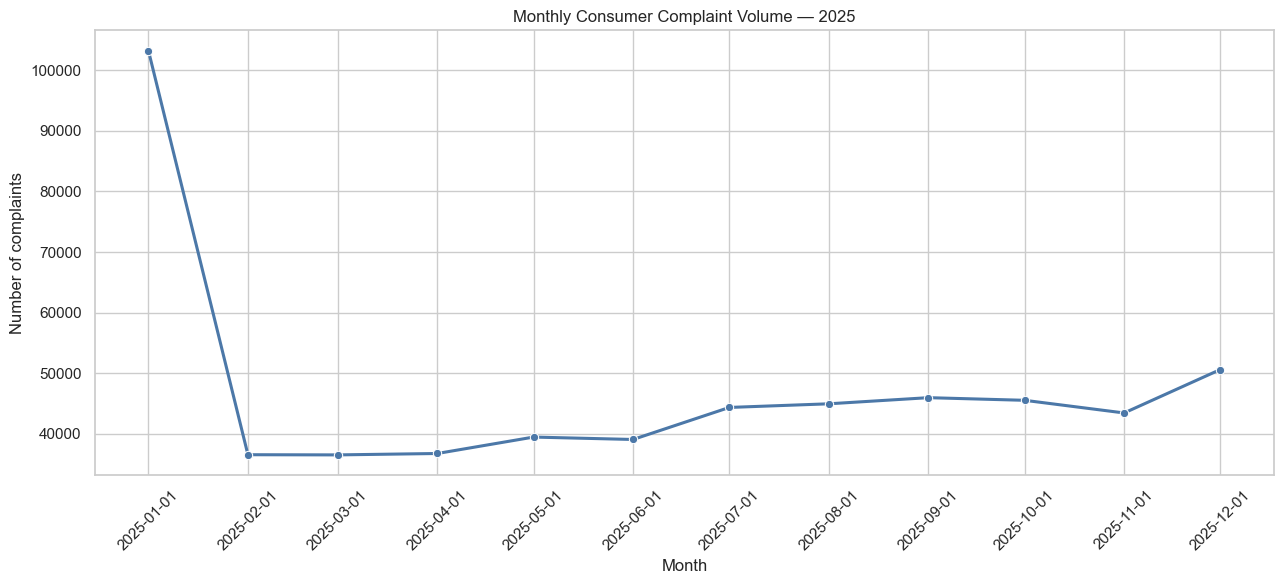

In [38]:
monthly_volume = (
    full_df
    .dropna(subset=["received_month"])
    .groupby("received_month")
    .size()
    .reset_index(name="complaints")
    .sort_values("received_month")
)

display(monthly_volume)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_volume,
    x="received_month",
    y="complaints",
    marker="o",
    linewidth=2.2,
    color="#4C78A8"
)

plt.title("Monthly Consumer Complaint Volume — 2025")
plt.xlabel("Month")
plt.ylabel("Number of complaints")
plt.xticks(monthly_volume["received_month"], rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### 2.2 Monthly Complaint Trends by Product

Monthly complaint volumes are separated by product to identify which products contributed to changes in the overall trend. The full dataset is used because the objective is to measure real complaint volumes.

,received_month,product,complaints
0,2025-01-01,Checking or savings account,18367
5,2025-02-01,Checking or savings account,5452
10,2025-03-01,Checking or savings account,5070
15,2025-04-01,Checking or savings account,5229
20,2025-05-01,Checking or savings account,5394
25,2025-06-01,Checking or savings account,5557
30,2025-07-01,Checking or savings account,6403
35,2025-08-01,Checking or savings account,6505
40,2025-09-01,Checking or savings account,6141
45,2025-10-01,Checking or savings account,6308


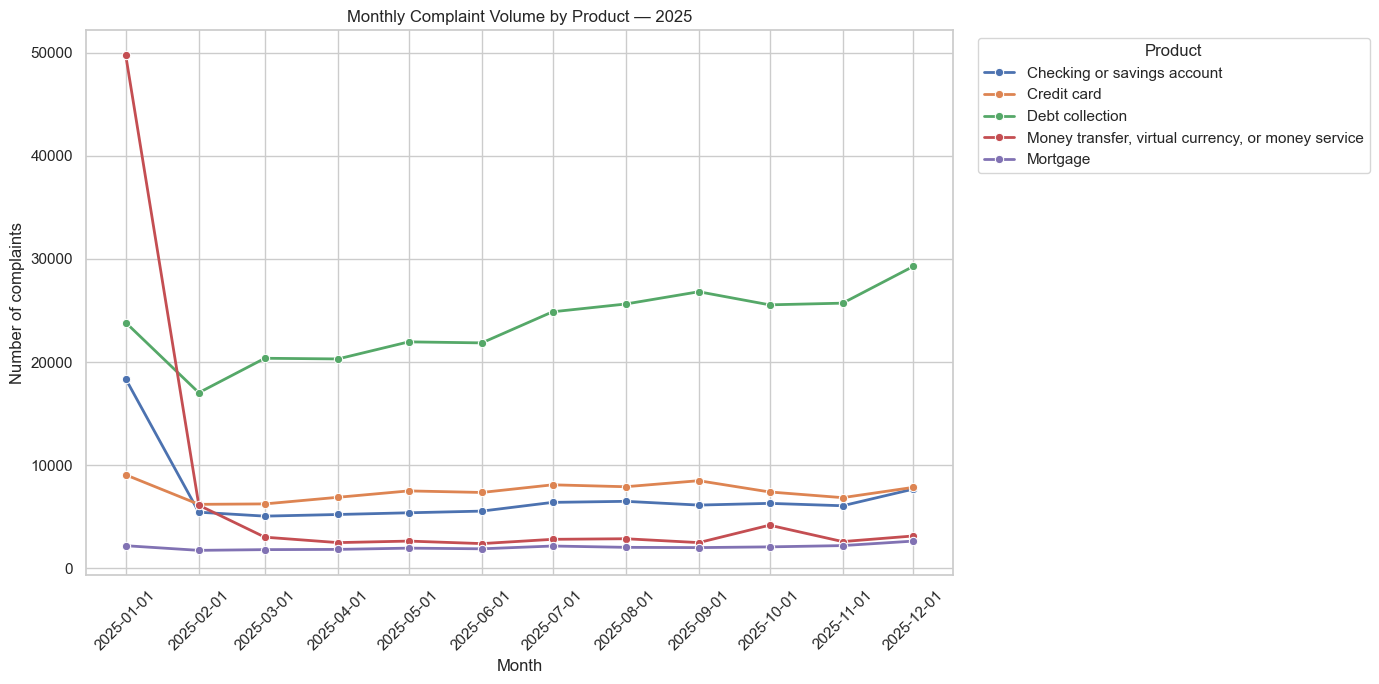

In [39]:
monthly_product = (
    full_df
    .dropna(subset=["received_month"])
    .groupby(["received_month", "product"])
    .size()
    .reset_index(name="complaints")
    .sort_values(["product", "received_month"])
)

display(monthly_product.head(10))

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_product,
    x="received_month",
    y="complaints",
    hue="product",
    marker="o",
    linewidth=2
)

plt.title("Monthly Complaint Volume by Product — 2025")
plt.xlabel("Month")
plt.ylabel("Number of complaints")
plt.xticks(monthly_volume["received_month"], rotation=45)
plt.legend(
    title="Product",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

### 2.3 Systematic Monthly Anomaly Check

Each product's monthly complaint volume is compared with its median monthly volume. The ratio helps identify unusually high months without relying only on visual inspection.

In [40]:
monthly_product["product_monthly_median"] = (
    monthly_product
    .groupby("product")["complaints"]
    .transform("median")
)

monthly_product["median_ratio"] = (
    monthly_product["complaints"] /
    monthly_product["product_monthly_median"]
)

monthly_anomalies = (
    monthly_product
    .sort_values("median_ratio", ascending=False)
    [[
        "received_month",
        "product",
        "complaints",
        "product_monthly_median",
        "median_ratio"
    ]]
    .head(10)
    .copy()
)

monthly_anomalies["median_ratio"] = (
    monthly_anomalies["median_ratio"].round(2)
)

display(monthly_anomalies)

,received_month,product,complaints,product_monthly_median,median_ratio
3,2025-01-01,"Money transfer, virtual currency, or money ser...",49743,"2,851.00",17.45
0,2025-01-01,Checking or savings account,18367,"6,108.50",3.01
8,2025-02-01,"Money transfer, virtual currency, or money ser...",6128,"2,851.00",2.15
48,2025-10-01,"Money transfer, virtual currency, or money ser...",4193,"2,851.00",1.47
59,2025-12-01,Mortgage,2651,"2,033.50",1.30
55,2025-12-01,Checking or savings account,7692,"6,108.50",1.26
1,2025-01-01,Credit card,9073,"7,464.00",1.22
57,2025-12-01,Debt collection,29279,"24,351.00",1.20
41,2025-09-01,Credit card,8504,"7,464.00",1.14
58,2025-12-01,"Money transfer, virtual currency, or money ser...",3149,"2,851.00",1.10


### 2.4 Investigation of the Largest Monthly Anomaly

The product-month combination with the highest volume relative to its typical monthly level is examined by calendar day, company and issue. This determines whether the increase is broadly distributed or concentrated in a small number of categories.

In [41]:
largest_anomaly = monthly_product.loc[
    monthly_product["median_ratio"].idxmax()
]

anomaly_month = largest_anomaly["received_month"]
anomaly_product = largest_anomaly["product"]

anomaly_data = full_df[
    (full_df["received_month"] == anomaly_month) &
    (full_df["product"] == anomaly_product)
].copy()

print("Anomaly month:", anomaly_month.strftime("%B %Y"))
print("Product:", anomaly_product)
print("Complaints:", f"{len(anomaly_data):,}")
print("Ratio to product median:", round(largest_anomaly["median_ratio"], 2))

daily_anomaly = (
    anomaly_data
    .groupby("received_date")
    .size()
    .reset_index(name="complaints")
    .sort_values("received_date")
)

print("\nDAILY DISTRIBUTION")
display(daily_anomaly)

print("\nTOP 10 COMPANIES")
display(
    anomaly_data["company"]
    .value_counts()
    .head(10)
    .rename_axis("company")
    .reset_index(name="complaints")
)

print("\nTOP 10 ISSUES")
display(
    anomaly_data["issue"]
    .value_counts()
    .head(10)
    .rename_axis("issue")
    .reset_index(name="complaints")
)

Anomaly month: January 2025
Product: Money transfer, virtual currency, or money service
Complaints: 49,743
Ratio to product median: 17.45

DAILY DISTRIBUTION


,received_date,complaints
0,2025-01-01,21
1,2025-01-02,70
2,2025-01-03,72
3,2025-01-04,42
4,2025-01-05,33
5,2025-01-06,81
6,2025-01-07,71
7,2025-01-08,56
8,2025-01-09,71
9,2025-01-10,61



TOP 10 COMPANIES


,company,complaints
0,"Block, Inc.",30466
1,"Early Warning Services, LLC",16521
2,JPMORGAN CHASE & CO.,516
3,"BANK OF AMERICA, NATIONAL ASSOCIATION",358
4,"Paypal Holdings, Inc",342
5,WELLS FARGO & COMPANY,328
6,"Coinbase, Inc.",143
7,ROBINHOOD MARKETS INC.,127
8,CAPITAL ONE FINANCIAL CORPORATION,92
9,NAVY FEDERAL CREDIT UNION,82



TOP 10 ISSUES


,issue,complaints
0,Other transaction problem,42521
1,Fraud or scam,2363
2,Unauthorized transactions or other transaction...,1313
3,Other service problem,1111
4,Confusing or missing disclosures,1096
5,Money was not available when promised,321
6,Trouble accessing funds in your mobile or digi...,274
7,Wrong amount charged or received,165
8,"Managing, opening, or closing your mobile wall...",162
9,Unexpected or other fees,157


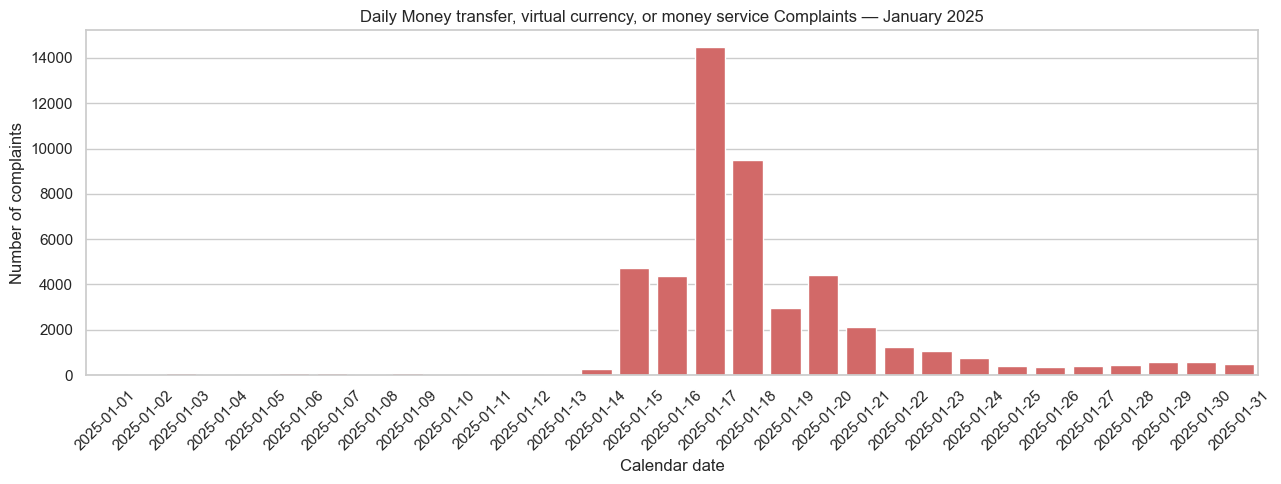

In [42]:
plt.figure(figsize=(13, 5))

sns.barplot(
    data=daily_anomaly,
    x="received_date",
    y="complaints",
    color="#E45756"
)

plt.title(
    f"Daily {anomaly_product} Complaints — "
    f"{anomaly_month.strftime('%B %Y')}"
)
plt.xlabel("Calendar date")
plt.ylabel("Number of complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Preliminary interpretation:**  
Monthly complaint volumes varied substantially during 2025. The product-level analysis shows that the exceptionally high overall volume in January was primarily associated with money-transfer complaints. The anomaly assessment compares every product-month combination with its typical monthly volume, while the daily, company and issue breakdowns help determine whether the largest increase was broadly distributed or concentrated.

The timestamp component does not invalidate the monthly analysis. It records different submission times within the same calendar day. Separate date and month variables were therefore used to ensure correct aggregation.

## 3. Company-Level Complaint Analysis

This section examines how complaint volume is distributed across companies. The full cleaned dataset is used to preserve actual complaint counts. Higher complaint volume does not necessarily indicate poorer performance because companies differ in customer base, transaction volume and market share.

### 3.1 Companies with the Highest Complaint Volumes

Complaint counts, percentage shares and cumulative shares are calculated to determine whether complaints are concentrated among a relatively small number of companies.

In [43]:
company_volume = (
    full_df["company"]
    .value_counts()
    .rename_axis("company")
    .reset_index(name="complaints")
)

company_volume["percentage"] = (
    company_volume["complaints"] / len(full_df) * 100
)

company_volume["cumulative_percentage"] = (
    company_volume["percentage"].cumsum()
)

company_volume_display = company_volume.copy()
company_volume_display["percentage"] = (
    company_volume_display["percentage"].round(2)
)
company_volume_display["cumulative_percentage"] = (
    company_volume_display["cumulative_percentage"].round(2)
)

print("Total companies:", full_df["company"].nunique())
print(
    "Top 10 company share:",
    f"{company_volume.head(10)['percentage'].sum():.2f}%"
)

display(company_volume_display.head(15))

Total companies: 3326
Top 10 company share: 43.82%


,company,complaints,percentage,cumulative_percentage
0,"Block, Inc.",46720,8.24,8.24
1,"EQUIFAX, INC.",34954,6.17,14.41
2,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",31174,5.50,19.91
3,Experian Information Solutions Inc.,26242,4.63,24.54
4,CAPITAL ONE FINANCIAL CORPORATION,21700,3.83,28.37
5,"Early Warning Services, LLC",20559,3.63,32.00
6,JPMORGAN CHASE & CO.,19230,3.39,35.39
7,Resurgent Capital Services L.P.,17827,3.15,38.54
8,WELLS FARGO & COMPANY,15216,2.69,41.23
9,"CITIBANK, N.A.",14694,2.59,43.82


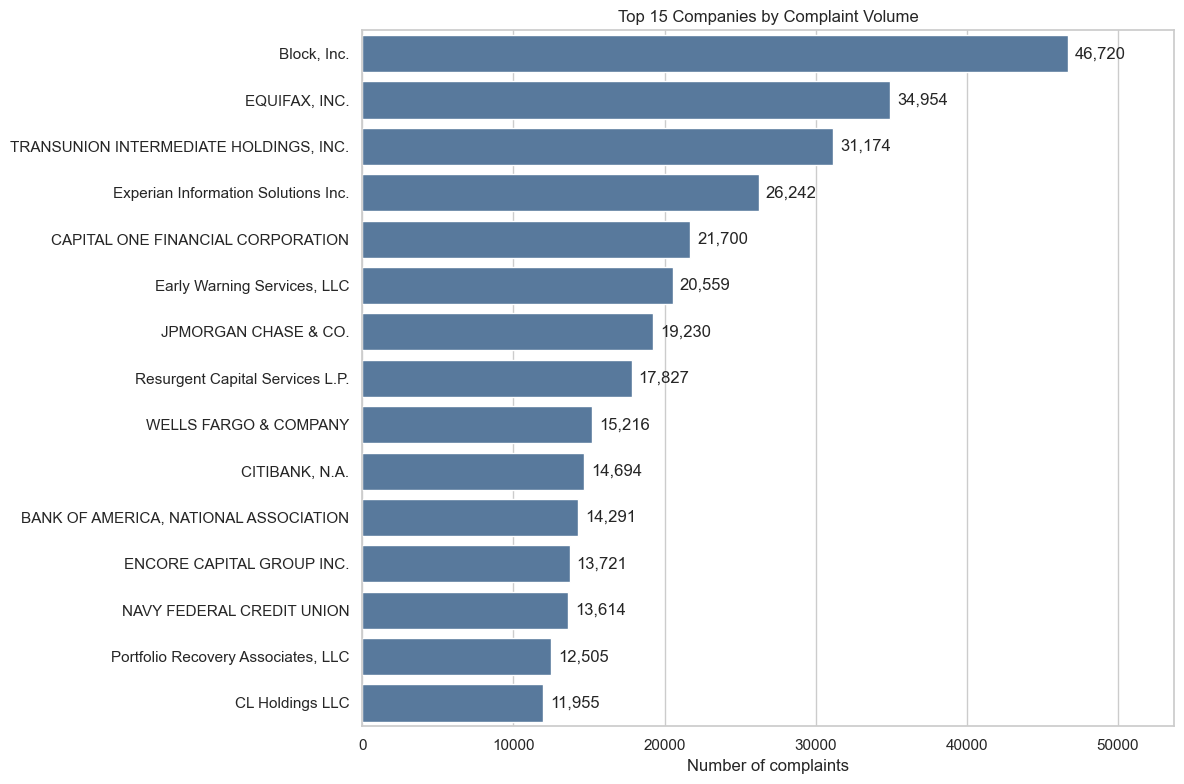

In [44]:
top_companies = company_volume.head(15).copy()

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=top_companies,
    x="complaints",
    y="company",
    color="#4C78A8"
)

for container in ax.containers:
    labels = [f"{value:,.0f}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=5)

ax.set_xlim(0, top_companies["complaints"].max() * 1.15)

plt.title("Top 15 Companies by Complaint Volume")
plt.xlabel("Number of complaints")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Interpretation:**  
Block, Inc. recorded the highest complaint volume, followed by Equifax, TransUnion and Experian. The leading companies include fintech providers, credit-reporting companies, banks and debt-collection firms. Because their activities and customer bases differ substantially, the overall ranking shows complaint concentration but does not provide a direct measure of company performance. Product-level company analysis is therefore needed for more meaningful comparisons.

### 3.2 Leading Companies Within Each Product

Companies are ranked separately within each financial product. This provides greater context than the overall ranking because companies operating in different product markets are not directly compared.

In [45]:
#Top 5 companies per product
company_product_volume = (
    full_df
    .groupby(["product", "company"])
    .size()
    .reset_index(name="complaints")
)

top5_company_product = (
    company_product_volume
    .sort_values(
        ["product", "complaints"],
        ascending=[True, False]
    )
    .groupby("product", group_keys=False)
    .head(5)
)

display(top5_company_product.reset_index(drop=True))

,product,company,complaints
0,Checking or savings account,NAVY FEDERAL CREDIT UNION,10606
1,Checking or savings account,JPMORGAN CHASE & CO.,8937
2,Checking or savings account,WELLS FARGO & COMPANY,8181
3,Checking or savings account,CAPITAL ONE FINANCIAL CORPORATION,7912
4,Checking or savings account,"BANK OF AMERICA, NATIONAL ASSOCIATION",6680
5,Credit card,CAPITAL ONE FINANCIAL CORPORATION,9923
6,Credit card,"CITIBANK, N.A.",8620
7,Credit card,"EQUIFAX, INC.",8358
8,Credit card,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",6600
9,Credit card,SYNCHRONY FINANCIAL,6570


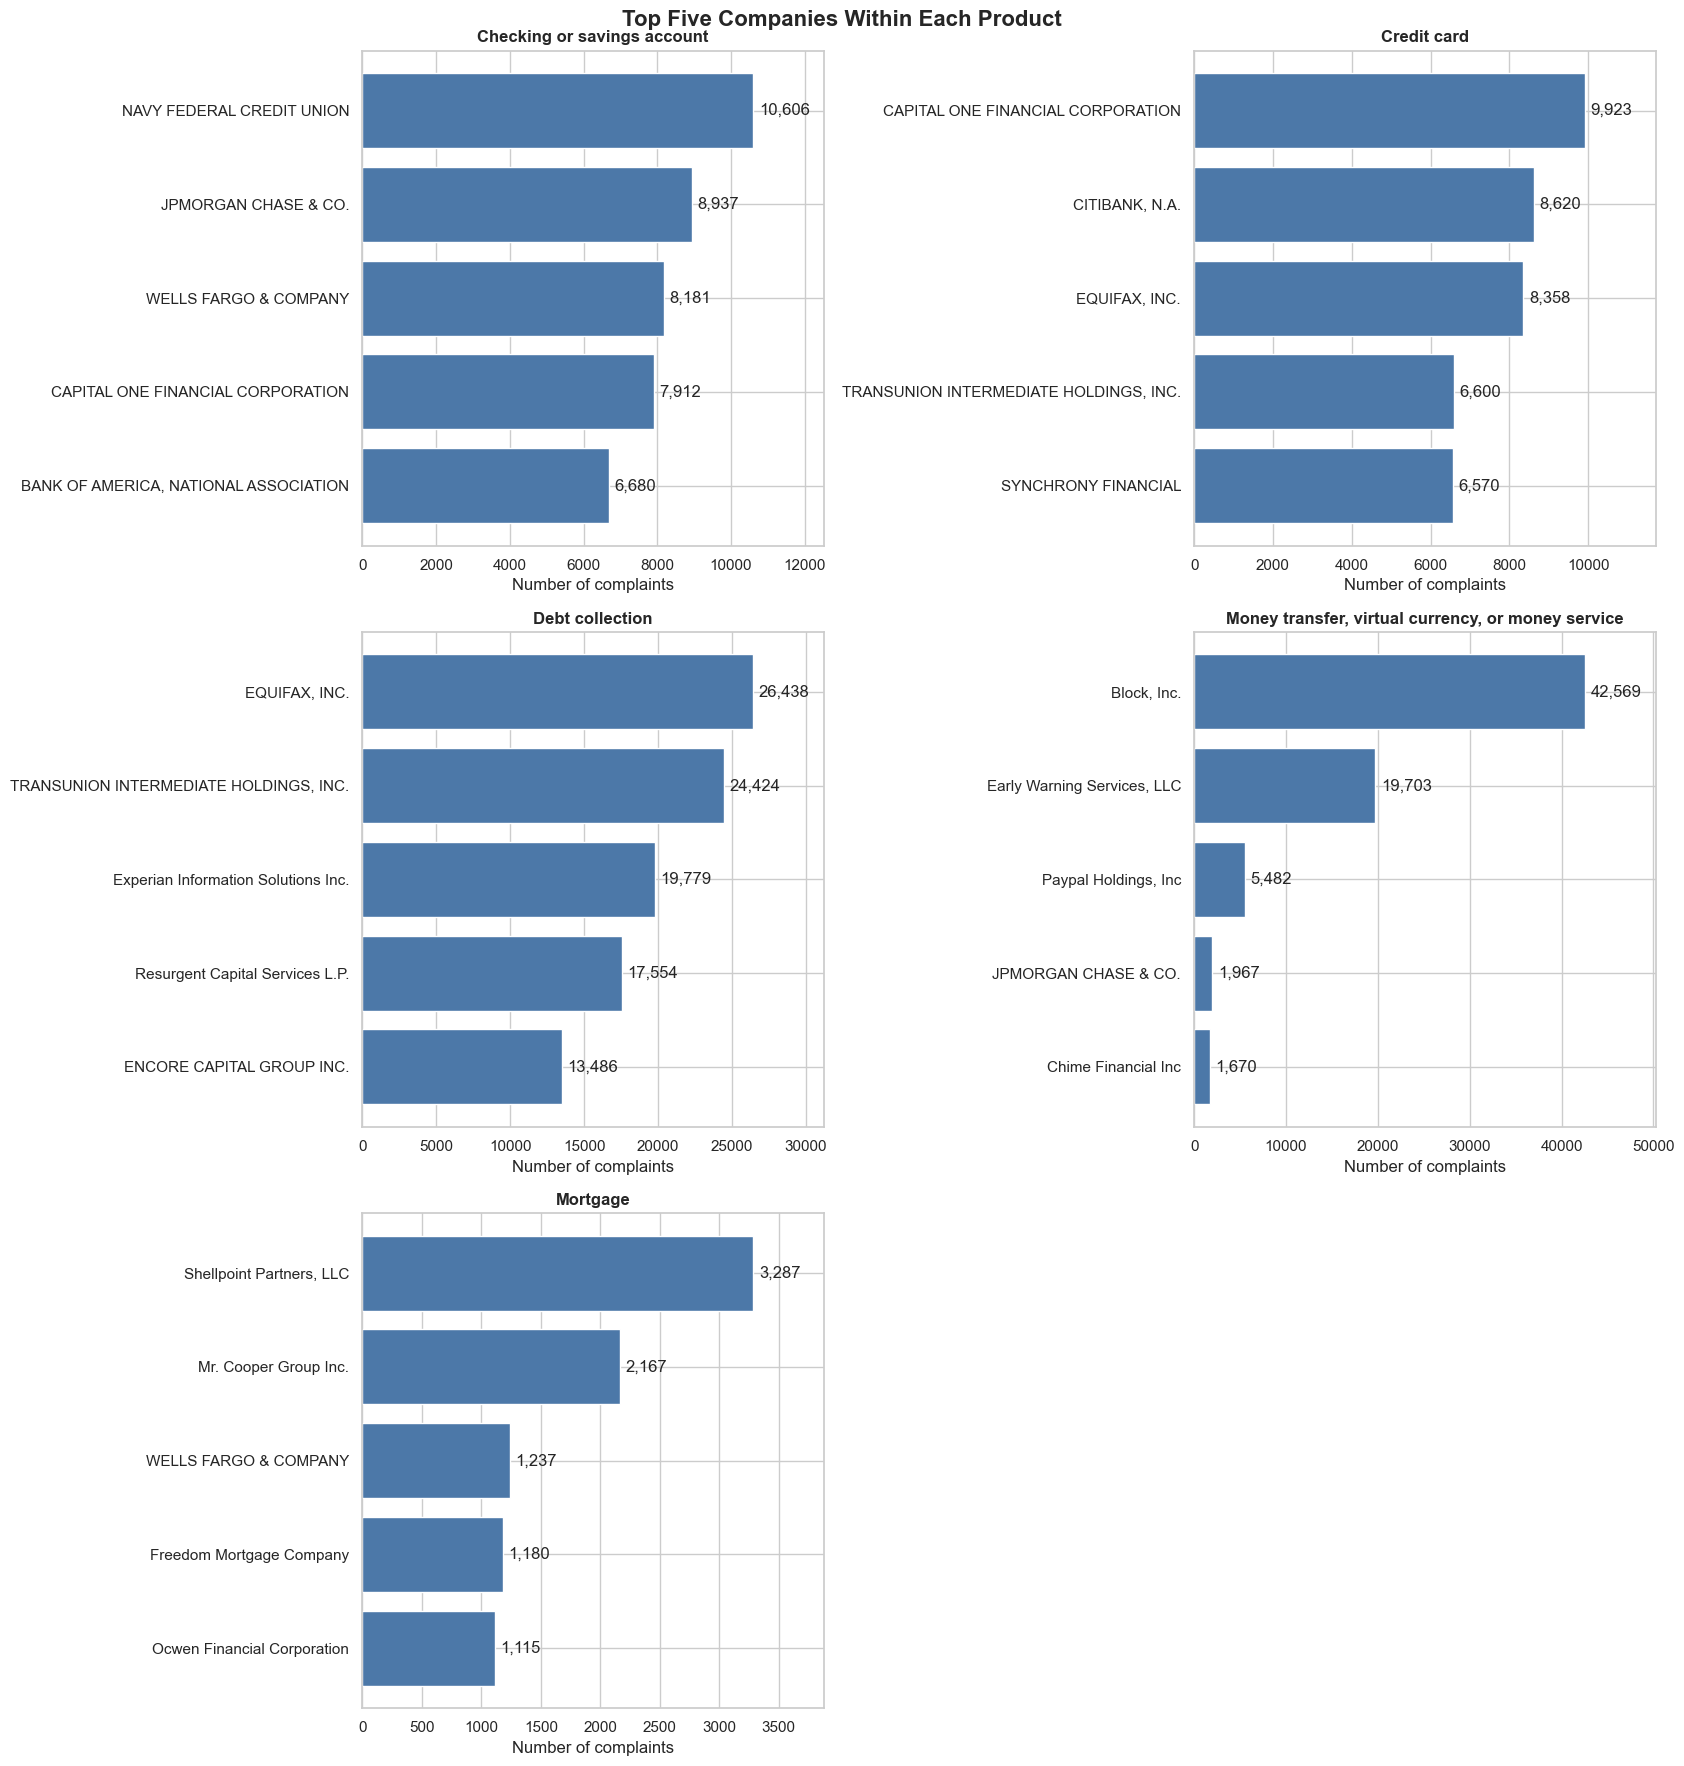

In [46]:
products = top5_company_product["product"].unique()

fig, axes = plt.subplots(3, 2, figsize=(17, 18))
axes = axes.flatten()

for ax, product in zip(axes, products):

    plot_data = (
        top5_company_product[
            top5_company_product["product"] == product
        ]
        .sort_values("complaints")
    )

    bars = ax.barh(
        plot_data["company"],
        plot_data["complaints"],
        color="#4C78A8"
    )

    ax.bar_label(
        bars,
        labels=[f"{x:,.0f}" for x in plot_data["complaints"]],
        padding=4
    )

    ax.set_title(product, fontweight="bold")
    ax.set_xlabel("Number of complaints")
    ax.set_ylabel("")
    ax.set_xlim(0, plot_data["complaints"].max() * 1.18)

for ax in axes[len(products):]:
    ax.remove()

plt.suptitle(
    "Top Five Companies Within Each Product",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpretation:**  
Company concentration differs considerably across products. Navy Federal Credit Union leads checking and savings complaints, while Capital One has the highest credit-card complaint volume. Debt-collection complaints are led by Equifax, TransUnion and Experian.

Money-transfer complaints show the strongest company concentration: Block, Inc. recorded 42,569 complaints, substantially more than Early Warning Services and the remaining companies. Shellpoint Partners recorded the highest mortgage complaint volume.

These rankings indicate where complaint records are concentrated within each product. They should not be interpreted as direct measures of company quality because customer-base and transaction-volume information is unavailable.

### 3.3 Company Share Within Each Product

Each leading company's complaint count is divided by the total complaint volume of its product. This measures complaint concentration within each product while preserving the actual distribution of the full dataset.

In [47]:
product_totals = (
    full_df
    .groupby("product")
    .size()
    .reset_index(name="product_total")
)

company_product_share = company_product_volume.merge(
    product_totals,
    on="product",
    how="left"
)

company_product_share["product_share_percentage"] = (
    company_product_share["complaints"] /
    company_product_share["product_total"] * 100
)

top5_company_share = (
    company_product_share
    .sort_values(
        ["product", "complaints"],
        ascending=[True, False]
    )
    .groupby("product", group_keys=False)
    .head(5)
    .copy()
)

top5_company_share["product_share_percentage"] = (
    top5_company_share["product_share_percentage"].round(2)
)

display(
    top5_company_share[
        [
            "product",
            "company",
            "complaints",
            "product_share_percentage"
        ]
    ].reset_index(drop=True)
)

,product,company,complaints,product_share_percentage
0,Checking or savings account,NAVY FEDERAL CREDIT UNION,10606,12.60
1,Checking or savings account,JPMORGAN CHASE & CO.,8937,10.61
2,Checking or savings account,WELLS FARGO & COMPANY,8181,9.72
3,Checking or savings account,CAPITAL ONE FINANCIAL CORPORATION,7912,9.40
4,Checking or savings account,"BANK OF AMERICA, NATIONAL ASSOCIATION",6680,7.93
5,Credit card,CAPITAL ONE FINANCIAL CORPORATION,9923,11.03
6,Credit card,"CITIBANK, N.A.",8620,9.58
7,Credit card,"EQUIFAX, INC.",8358,9.29
8,Credit card,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",6600,7.34
9,Credit card,SYNCHRONY FINANCIAL,6570,7.30


In [48]:
top5_concentration = (
    top5_company_share
    .groupby("product")
    .agg(
        top_5_complaints=("complaints", "sum"),
        top_5_share=("product_share_percentage", "sum")
    )
    .reset_index()
)

top5_concentration["top_5_share"] = (
    top5_concentration["top_5_share"].round(2)
)

display(
    top5_concentration.sort_values(
        "top_5_share",
        ascending=False
    )
)

,product,top_5_complaints,top_5_share
3,"Money transfer, virtual currency, or money ser...",71391,84.36
0,Checking or savings account,42316,50.26
1,Credit card,40071,44.54
4,Mortgage,8986,36.38
2,Debt collection,101681,35.90


**Interpretation:**  
Money-transfer complaints show the highest company concentration. Block, Inc. alone accounts for 50.31% of all money-transfer complaints, while Block and Early Warning Services together account for approximately 73.59%. The five leading companies collectively represent approximately 84.36% of this product's complaints.

Checking and savings complaints are moderately concentrated, with the five leading companies accounting for approximately 50.26%. Credit-card complaints have a top-five concentration of approximately 44.54%. Debt collection and mortgage complaints are more widely distributed across companies, with top-five shares of approximately 35.90% and 36.38%, respectively.

These percentages describe concentration within the CFPB dataset and should not be interpreted as market share or complaint rates per customer.

## 4. Geographic Complaint Analysis

This section examines the geographic distribution of complaints using the full cleaned dataset. Complaint counts represent actual CFPB complaint volumes but are not adjusted for differences in state population.

In [49]:
state_volume = (
    full_df["state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="complaints")
)

state_volume["percentage"] = (
    state_volume["complaints"] / len(full_df) * 100
).round(2)

display(state_volume.head(15))

,state,complaints,percentage
0,TX,84779,14.96
1,FL,57926,10.22
2,CA,57746,10.19
3,GA,39340,6.94
4,NY,30432,5.37
5,IL,25015,4.41
6,NC,20612,3.64
7,PA,19041,3.36
8,VA,16170,2.85
9,NJ,15601,2.75


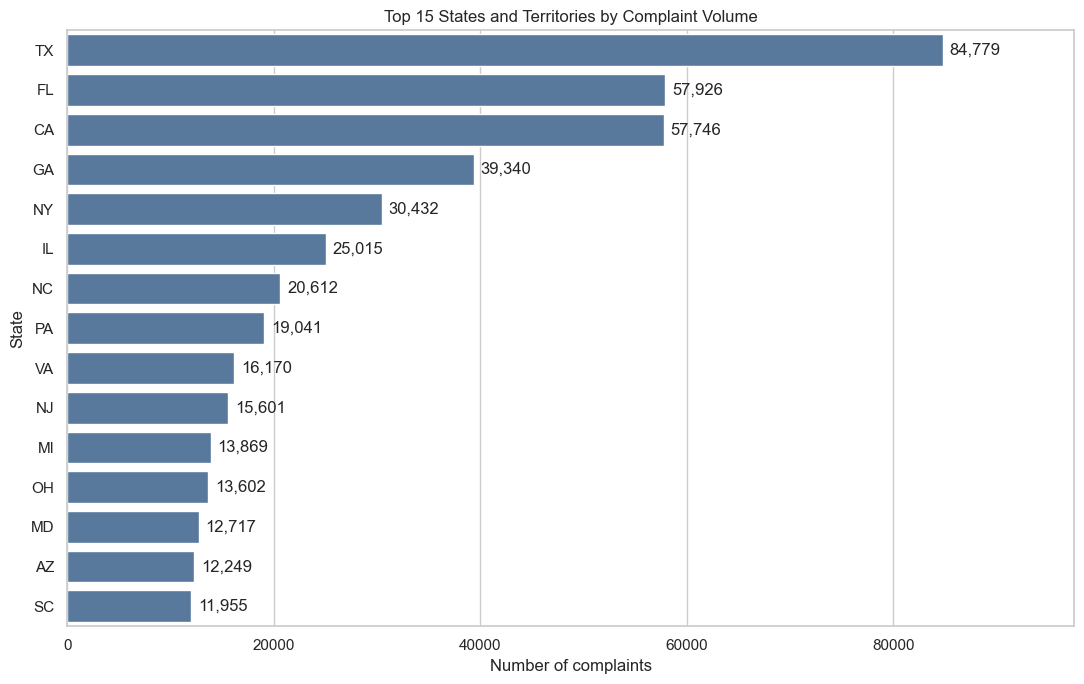

In [50]:
top_states = state_volume.head(15)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=top_states,
    x="complaints",
    y="state",
    color="#4C78A8"
)

for container in ax.containers:
    labels = [f"{value:,.0f}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=5)

ax.set_xlim(0, top_states["complaints"].max() * 1.15)

plt.title("Top 15 States and Territories by Complaint Volume")
plt.xlabel("Number of complaints")
plt.ylabel("State")
plt.tight_layout()
plt.show()

**Interpretation:**  
Texas recorded the highest complaint volume, followed by Florida, California, Georgia and New York. The differences reflect the number of complaints present in the CFPB dataset and may be influenced by population size, financial-service usage and reporting behaviour. Therefore, the ranking should not be interpreted as evidence that consumers in one state necessarily experience more problems than consumers in another.

### 4.2 Product Mix Within Leading States

The product composition of complaints is compared across the ten states with the highest overall complaint volumes. Percentages are used instead of absolute counts so that differences in state size do not dominate the comparison.

In [51]:
top10_states = state_volume.head(10)["state"].tolist()

state_product_counts = (
    full_df[
        full_df["state"].isin(top10_states)
    ]
    .groupby(["state", "product"])
    .size()
    .unstack(fill_value=0)
    .reindex(top10_states)
)

state_product_percentage = (
    state_product_counts
    .div(state_product_counts.sum(axis=1), axis=0)
    * 100
)

display(state_product_percentage.round(2))

product,Checking or savings account,Credit card,Debt collection,"Money transfer, virtual currency, or money service",Mortgage
state,,,,,
TX,9.98,14.25,62.17,10.79,2.81
FL,14.25,14.92,54.73,11.33,4.76
CA,18.67,20.57,41.21,14.34,5.21
GA,12.83,9.44,60.42,13.81,3.50
NY,20.86,21.48,36.30,17.67,3.70
IL,13.64,15.03,41.55,26.12,3.65
NC,14.27,13.43,52.57,15.26,4.46
PA,15.77,15.36,51.70,12.71,4.46
VA,15.47,23.02,43.64,13.27,4.59


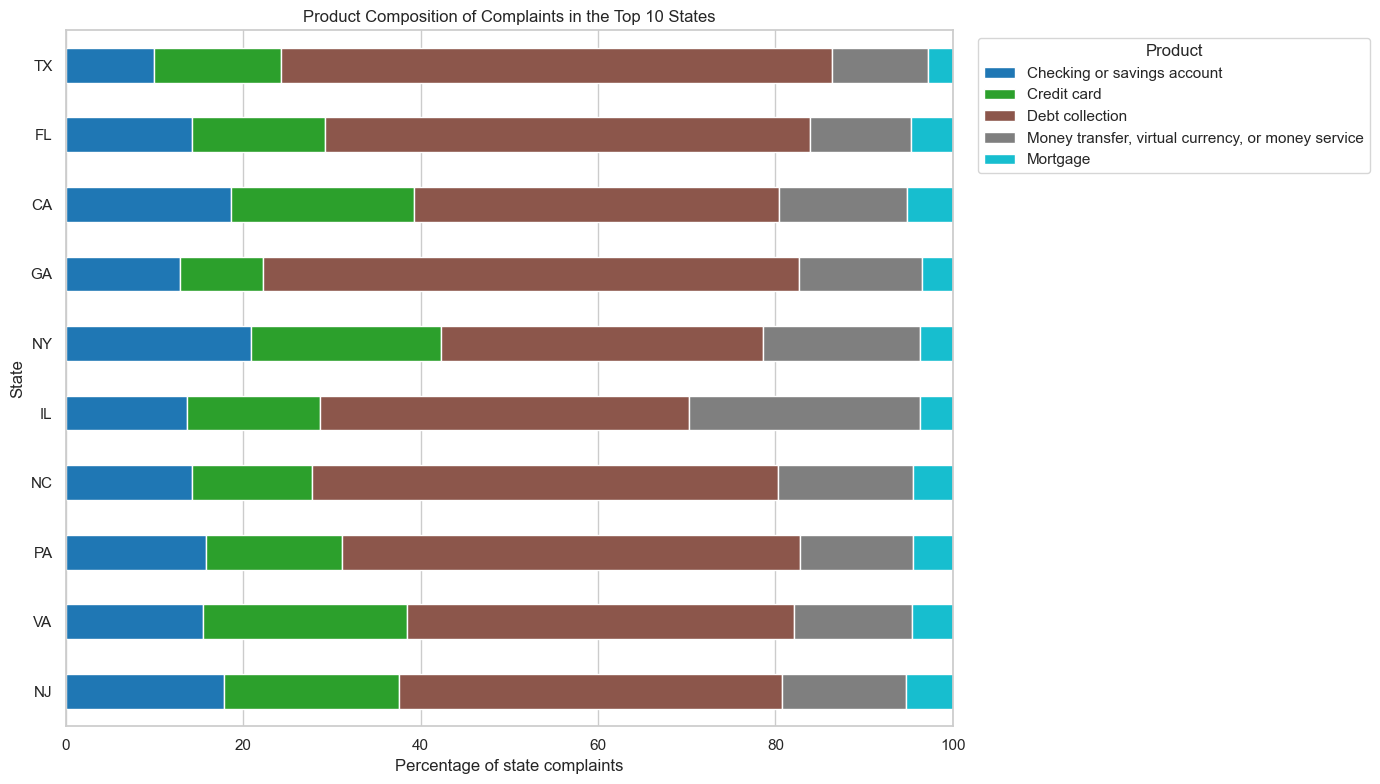

In [52]:
ax = state_product_percentage.plot(
    kind="barh",
    stacked=True,
    figsize=(14, 8),
    colormap="tab10"
)

ax.invert_yaxis()

plt.title("Product Composition of Complaints in the Top 10 States")
plt.xlabel("Percentage of state complaints")
plt.ylabel("State")
plt.xlim(0, 100)

plt.legend(
    title="Product",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

**Interpretation:**  
Debt collection represents the largest complaint category in all ten leading states. Its share appears particularly high in Texas, Georgia and Florida, while states such as New York, California and New Jersey have a more balanced product distribution.

Checking and savings complaints make up a comparatively larger share in New York, California and New Jersey. Credit-card complaints also account for a noticeable proportion in California, New York, Virginia and New Jersey. Mortgage complaints represent the smallest share across all ten states.

These percentages compare the composition of complaints within each state and do not measure state-level complaint rates.

## 5. Company Response and Timeliness KPIs

This section evaluates how companies responded to consumer complaints and whether responses were submitted within the CFPB's required timeframe. The full cleaned dataset is used because these KPIs should reflect actual complaint outcomes.

### 5.1 Overall Company Response Distribution

Company responses are summarised by response category to identify the most common complaint-resolution outcomes.

In [53]:
response_distribution = (
    full_df["company_response_to_consumer"]
    .value_counts()
    .rename_axis("company_response")
    .reset_index(name="complaints")
)

response_distribution["percentage"] = (
    response_distribution["complaints"] /
    len(full_df) * 100
).round(2)

display(response_distribution)

,company_response,complaints,percentage
0,Closed with explanation,443349,78.23
1,Closed with non-monetary relief,97002,17.12
2,Closed with monetary relief,23196,4.09
3,Untimely response,3120,0.55
4,In progress,27,0.00


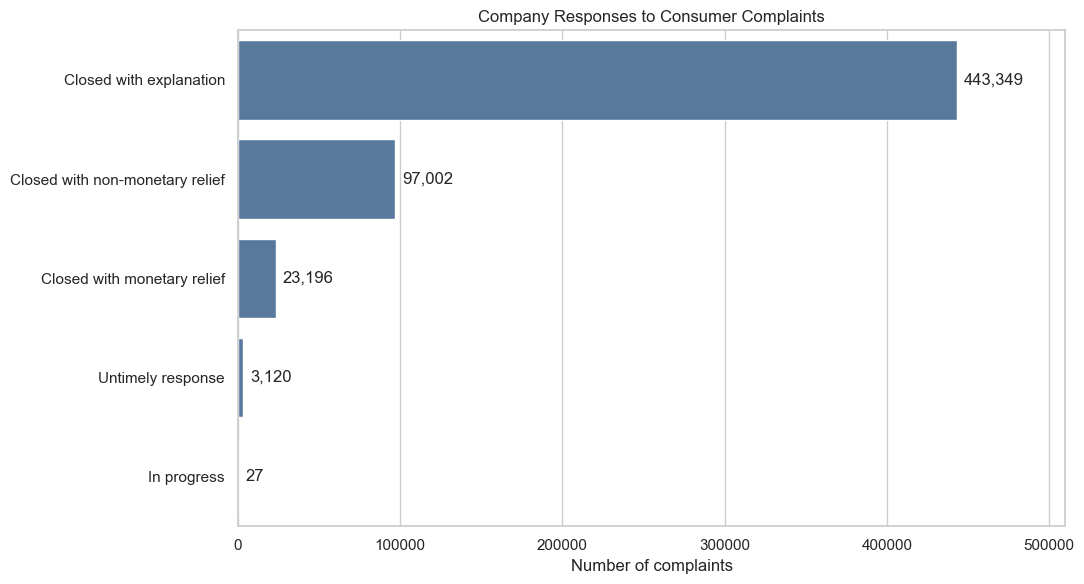

In [54]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=response_distribution,
    x="complaints",
    y="company_response",
    color="#4C78A8"
)

for container in ax.containers:
    labels = [f"{value:,.0f}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=5)

ax.set_xlim(
    0,
    response_distribution["complaints"].max() * 1.15
)

plt.title("Company Responses to Consumer Complaints")
plt.xlabel("Number of complaints")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 5.2 Overall Timely-Response Rate

The timely-response rate measures the proportion of complaints for which companies responded within the required timeframe.

In [55]:
timely_distribution = (
    full_df["timely_response"]
    .value_counts()
    .rename_axis("timely_response")
    .reset_index(name="complaints")
)

timely_distribution["percentage"] = (
    timely_distribution["complaints"] /
    len(full_df) * 100
).round(2)

timely_rate = (
    full_df["timely_response"]
    .eq("Yes")
    .mean() * 100
)

untimely_rate = (
    full_df["timely_response"]
    .eq("No")
    .mean() * 100
)

display(timely_distribution)

print(f"Timely-response rate: {timely_rate:.2f}%")
print(f"Untimely-response rate: {untimely_rate:.2f}%")

,timely_response,complaints,percentage
0,Yes,556143,98.14
1,No,10551,1.86


Timely-response rate: 98.14%
Untimely-response rate: 1.86%


**Interpretation:**  
Most complaints were closed with an explanation, accounting for approximately 78.23% of all records. Non-monetary relief was provided in approximately 17.12% of complaints, while monetary relief was recorded in approximately 4.09%.

Overall response timeliness was high: 98.14% of complaints received a timely response, while 1.86% were recorded as untimely. A timely response indicates that the company responded within the required timeframe; it does not necessarily indicate that the consumer received a satisfactory outcome.

### 5.3 Response Outcomes by Product

Company-response categories are converted into percentages within each product. This enables comparison across products despite differences in their total complaint volumes.

In [56]:
product_response_percentage = (
    pd.crosstab(
        full_df["product"],
        full_df["company_response_to_consumer"],
        normalize="index"
    ) * 100
)

response_order = [
    "Closed with explanation",
    "Closed with non-monetary relief",
    "Closed with monetary relief",
    "Untimely response",
    "In progress"
]

available_responses = [
    response for response in response_order
    if response in product_response_percentage.columns
]

product_response_percentage = (
    product_response_percentage[available_responses]
)

display(product_response_percentage.round(2))

company_response_to_consumer,Closed with explanation,Closed with non-monetary relief,Closed with monetary relief,Untimely response,In progress
product,,,,,
Checking or savings account,84.49,4.84,10.58,0.10,0.00
Credit card,66.70,20.57,12.65,0.07,0.00
Debt collection,73.29,25.58,0.16,0.96,0.01
"Money transfer, virtual currency, or money service",95.93,1.54,2.40,0.13,0.00
Mortgage,94.95,2.72,1.72,0.60,0.00


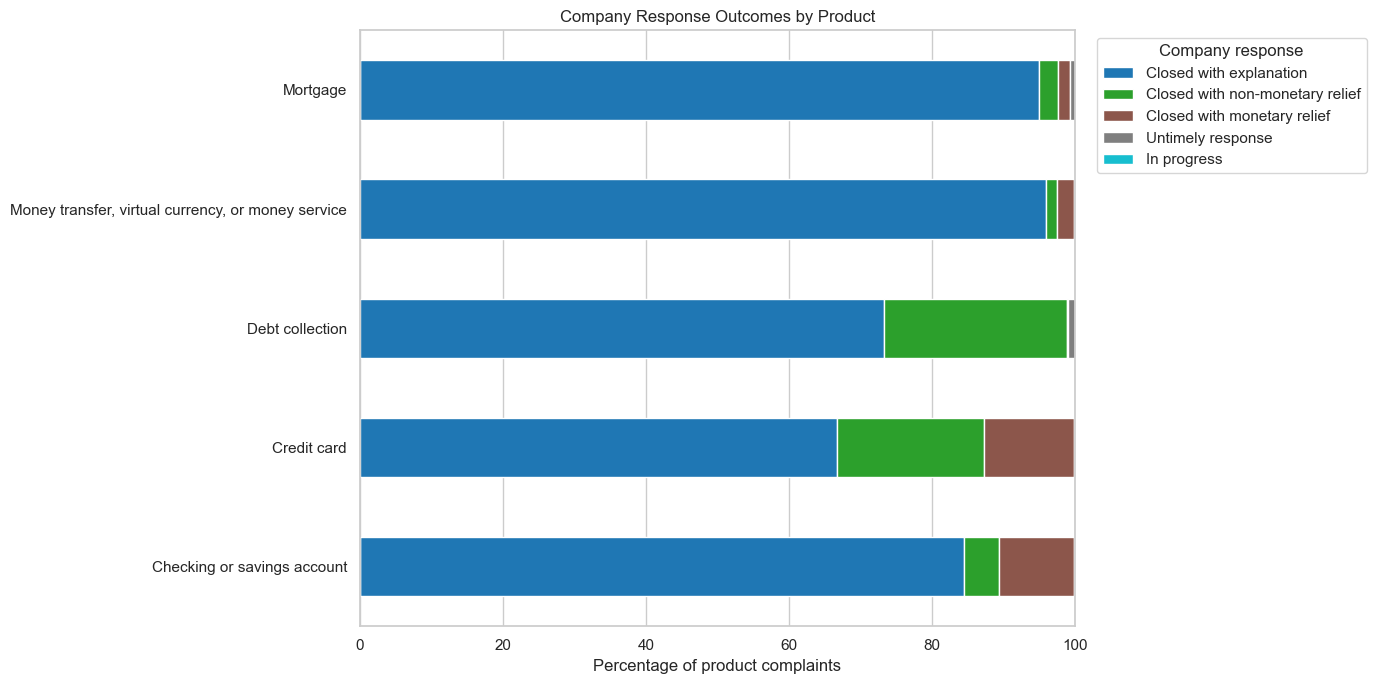

In [57]:
ax = product_response_percentage.plot(
    kind="barh",
    stacked=True,
    figsize=(14, 7),
    colormap="tab10"
)

plt.title("Company Response Outcomes by Product")
plt.xlabel("Percentage of product complaints")
plt.ylabel("")
plt.xlim(0, 100)

plt.legend(
    title="Company response",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 5.4 Timely-Response Rate by Product

Timely-response rates are calculated separately for each product to identify whether response performance differs across financial-product categories.

In [58]:
product_timeliness = (
    full_df
    .assign(
        timely_flag=full_df["timely_response"].eq("Yes")
    )
    .groupby("product")
    .agg(
        total_complaints=("timely_response", "size"),
        timely_responses=("timely_flag", "sum")
    )
    .reset_index()
)

product_timeliness["untimely_responses"] = (
    product_timeliness["total_complaints"] -
    product_timeliness["timely_responses"]
)

product_timeliness["timely_rate"] = (
    product_timeliness["timely_responses"] /
    product_timeliness["total_complaints"] * 100
)

product_timeliness = product_timeliness.sort_values(
    "timely_rate",
    ascending=False
)

display(product_timeliness.round(2))

,product,total_complaints,timely_responses,untimely_responses,timely_rate
1,Credit card,89979,89633,346,99.62
0,Checking or savings account,84194,83585,609,99.28
3,"Money transfer, virtual currency, or money ser...",84619,83592,1027,98.79
4,Mortgage,24697,24324,373,98.49
2,Debt collection,283205,275009,8196,97.11


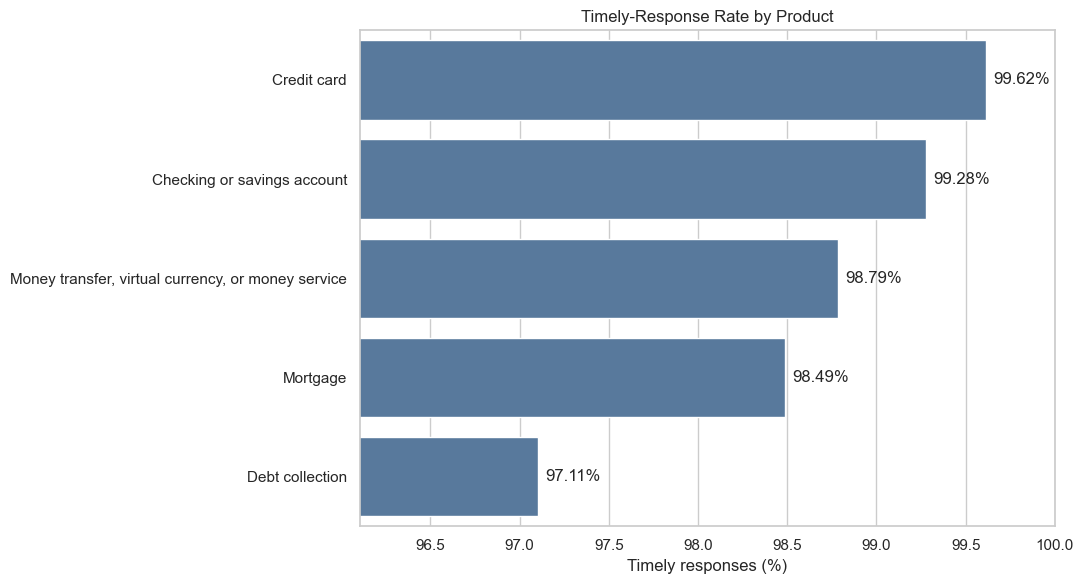

In [59]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=product_timeliness,
    x="timely_rate",
    y="product",
    color="#4C78A8"
)

for container in ax.containers:
    labels = [f"{value:.2f}%" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=5)

plt.xlim(
    product_timeliness["timely_rate"].min() - 1,
    100
)

plt.title("Timely-Response Rate by Product")
plt.xlabel("Timely responses (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Equal-Product Complaint Comparison

The balanced analytical dataset is used to compare complaint patterns across products without allowing the larger debt-collection category to dominate the analysis. It contains 30,000 records for four products and all 24,697 available mortgage complaints.

### 6.1 Leading Issues Within Each Product

The five most frequently reported issues are identified separately for each product. Within-product percentages are calculated to make the issue distributions comparable despite the smaller number of mortgage records.

In [60]:
balanced_issue_volume = (
    balanced_df
    .groupby(["product", "issue"])
    .size()
    .reset_index(name="complaints")
)

balanced_product_totals = (
    balanced_df
    .groupby("product")
    .size()
    .rename("product_total")
    .reset_index()
)

balanced_issue_volume = balanced_issue_volume.merge(
    balanced_product_totals,
    on="product",
    how="left"
)

balanced_issue_volume["issue_percentage"] = (
    balanced_issue_volume["complaints"] /
    balanced_issue_volume["product_total"] * 100
)

top5_issues_product = (
    balanced_issue_volume
    .sort_values(
        ["product", "complaints"],
        ascending=[True, False]
    )
    .groupby("product", group_keys=False)
    .head(5)
    .copy()
)

top5_issues_display = top5_issues_product.copy()
top5_issues_display["issue_percentage"] = (
    top5_issues_display["issue_percentage"].round(2)
)

display(
    top5_issues_display[
        [
            "product",
            "issue",
            "complaints",
            "issue_percentage"
        ]
    ].reset_index(drop=True)
)

,product,issue,complaints,issue_percentage
0,Checking or savings account,Managing an account,16034,53.45
1,Checking or savings account,Problem caused by your funds being low,4138,13.79
2,Checking or savings account,Closing an account,3662,12.21
3,Checking or savings account,Problem with a lender or other company chargin...,3450,11.50
4,Checking or savings account,Opening an account,2516,8.39
5,Credit card,Problem with a purchase shown on your statement,6636,22.12
6,Credit card,Incorrect information on your report,4619,15.40
7,Credit card,Getting a credit card,3616,12.05
8,Credit card,Problem with a company's investigation into an...,3368,11.23
9,Credit card,"Other features, terms, or problems",2771,9.24


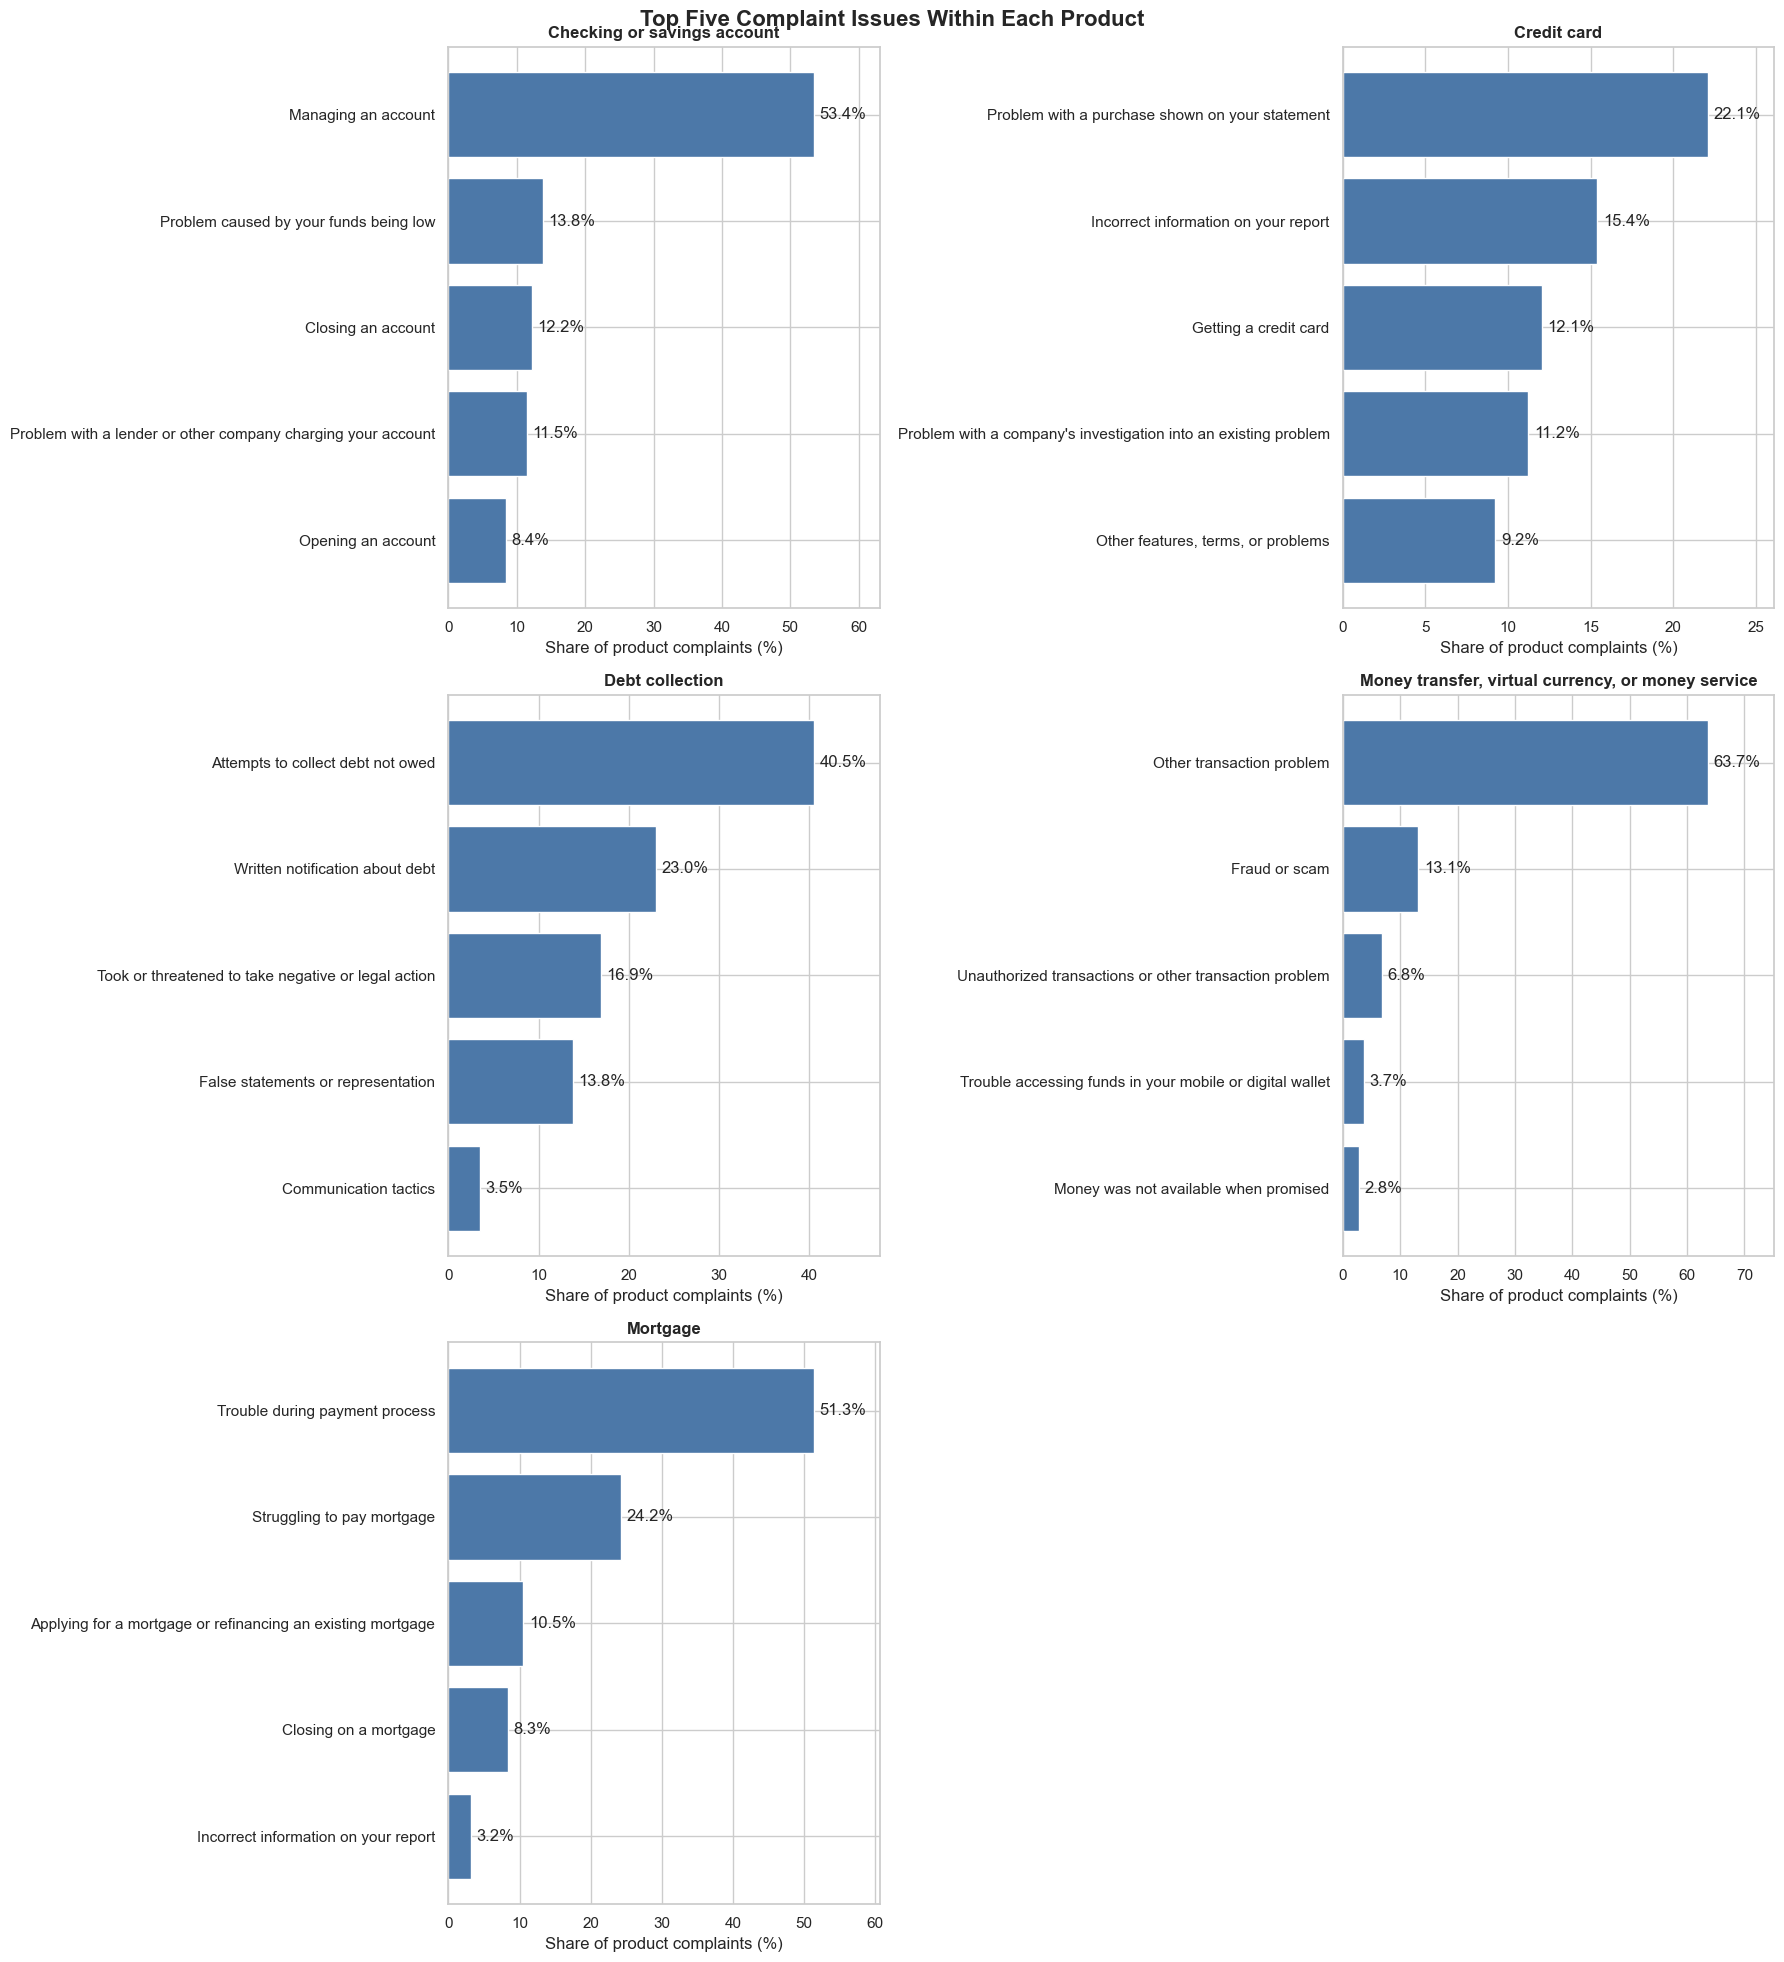

In [61]:
products = top5_issues_product["product"].unique()

fig, axes = plt.subplots(3, 2, figsize=(18, 20))
axes = axes.flatten()

for ax, product in zip(axes, products):

    plot_data = (
        top5_issues_product[
            top5_issues_product["product"] == product
        ]
        .sort_values("issue_percentage")
    )

    bars = ax.barh(
        plot_data["issue"],
        plot_data["issue_percentage"],
        color="#4C78A8"
    )

    ax.bar_label(
        bars,
        labels=[
            f"{value:.1f}%"
            for value in plot_data["issue_percentage"]
        ],
        padding=4
    )

    ax.set_title(product, fontweight="bold")
    ax.set_xlabel("Share of product complaints (%)")
    ax.set_ylabel("")
    ax.set_xlim(
        0,
        plot_data["issue_percentage"].max() * 1.18
    )

for ax in axes[len(products):]:
    ax.remove()

plt.suptitle(
    "Top Five Complaint Issues Within Each Product",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Interpretation:**  
The leading complaint issues differ substantially across financial products.

For checking and savings accounts, “Managing an account” dominates, representing 53.4% of the balanced sample. Credit-card complaints are more widely distributed, although problems with purchases shown on statements are the most frequent at 22.1%.

Debt-collection complaints are led by attempts to collect debt not owed, accounting for 40.5%, followed by written notifications about debt at 23.0%. Money-transfer complaints are highly concentrated in “Other transaction problem,” which represents 63.7%, while fraud or scams account for 13.1%.

Mortgage complaints primarily concern the payment process, representing 51.3%, followed by consumers struggling to pay their mortgage at 24.2%.

The balanced dataset prevents the larger debt-collection category from dominating the cross-product comparison. For the four sampled products, the percentages represent the reproducible 30,000-record samples; mortgage results represent all 24,697 available records.

## 7. Save Analytical Outputs

The main summary tables created during exploratory analysis are exported for later use in dashboards, reporting and subsequent project notebooks.

In [62]:
OUTPUT_DIR = Path("../outputs/notebook_3_eda")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

product_volume.to_csv(
    OUTPUT_DIR / "product_volume.csv",
    index=False
)

monthly_volume.to_csv(
    OUTPUT_DIR / "monthly_complaint_volume.csv",
    index=False
)

monthly_product.to_csv(
    OUTPUT_DIR / "monthly_product_volume.csv",
    index=False
)

company_volume.to_csv(
    OUTPUT_DIR / "company_volume.csv",
    index=False
)

top5_company_share.to_csv(
    OUTPUT_DIR / "top_companies_by_product.csv",
    index=False
)

state_volume.to_csv(
    OUTPUT_DIR / "state_volume.csv",
    index=False
)

state_product_percentage.reset_index().to_csv(
    OUTPUT_DIR / "state_product_composition.csv",
    index=False
)

response_distribution.to_csv(
    OUTPUT_DIR / "company_response_distribution.csv",
    index=False
)

product_timeliness.to_csv(
    OUTPUT_DIR / "product_timeliness_kpis.csv",
    index=False
)

top5_issues_display.to_csv(
    OUTPUT_DIR / "balanced_top_issues_by_product.csv",
    index=False
)

print("EDA tables saved to:", OUTPUT_DIR.resolve())
print("Number of files saved:", len(list(OUTPUT_DIR.glob("*.csv"))))

EDA tables saved to: /Users/ishika/Documents/AIProject/outputs/notebook_3_eda
Number of files saved: 10


# Notebook 3 Summary

This notebook explored 566,694 cleaned CFPB complaint records across five financial products. The full cleaned dataset was used for actual complaint volumes, temporal trends, companies, states and response KPIs. The balanced analytical dataset of 144,697 records was used only for equal-product issue comparisons.

## Key Findings

- Debt collection had the highest actual complaint volume with 283,205 records, while mortgage had the lowest with 24,697.
- January 2025 recorded an unusually high complaint volume, driven primarily by money-transfer complaints. The timestamp component did not create or inflate this pattern.
- Block, Inc. had the highest overall company complaint volume.
- Money-transfer complaints showed the strongest company concentration. Block represented 50.31% of money-transfer complaints, while the five leading companies represented approximately 84.36%.
- Texas recorded the highest state complaint volume, followed by Florida and California. These are raw volumes and are not adjusted for state population.
- Debt collection represented the largest complaint category across all ten leading states.
- Most complaints were closed with an explanation. Monetary relief was considerably less common than explanations or non-monetary relief.
- The overall timely-response rate was 98.14%.
- Balanced issue analysis showed distinct problems across products:
  - Checking and savings: managing an account
  - Credit card: problems with purchases shown on statements
  - Debt collection: attempts to collect debt not owed
  - Money transfer: other transaction problems
  - Mortgage: trouble during the payment process

## Analytical Limitations

- Company complaint volumes are not adjusted for customer base, transaction volume or market share.
- State complaint volumes are not adjusted for population.
- Complaint records represent consumers who submitted complaints to the CFPB and may not represent every consumer experience.
- Four products were sampled to 30,000 records in the balanced dataset, while all 24,697 mortgage records were retained.
- The analysis identifies associations and concentration patterns but does not establish causation.



In [63]:
print("NOTEBOOK 3 COMPLETE")
print("Full dataset analysed:", full_df.shape)
print("Balanced dataset analysed:", balanced_df.shape)
print("EDA tables saved:", len(list(OUTPUT_DIR.glob("*.csv"))))

NOTEBOOK 3 COMPLETE
Full dataset analysed: (566694, 30)
Balanced dataset analysed: (144697, 26)
EDA tables saved: 10
